# Final Model on the IEEE-CIS Test Set

## 1. Introduction

Our final IEEE-CIS model is **M2 CatBoost**, using the 115 selected features and tuned hyperparameters from notebook 06. It achieved a validation PR-AUC of **0.667**.

The later experiments did not show any meaningful improvement over M2:

- **M3** (pseudo-labelling, notebook 07): improved PR-AUC by only 0.0005 on average across 3 seeds, which is too small to distinguish from seed variation
- **M4** (anomaly score features, notebook 08): achieved 0.663 with `iforest_all` and 0.657 with `pca_error`, both below M2

This notebook covers three steps:

1. **Section 4:** Select how many transactions to flag per day using validation data only
2. **Section 5:** Apply the final model to the test set
3. **Section 6:** Compare test performance against validation performance

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

pd.set_option("display.max_columns", 100)

SEED = 100
PROCESSED_DIR = Path("../data/processed")

# the selected features and the validation scores of the final model, from notebook 06
TUNING_DIR = Path("../results/ieee/m2_tuning")

# the test runs are saved here, so a rerun loads them instead of training again
RUNS_DIR = Path("../results/ieee/final_test")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Data Loading and Preparation

Data preparation follows notebook 06 Section 2, but we also keep the test rows for retraining and evaluation during the test period.

- **Categorical columns:** stored as pandas categories, with `"missing"` as a separate category
- **Code columns:** the 6 columns (`card1`, `card2`, `card3`, `card5`, `addr1`, `addr2`) are converted to text categories (e.g. `315.0` -> `"315"`)
- **Numeric columns:** stored as `float32`

The test set contains the latest 20% of transactions, following the chronological split from notebook 04 Section 3.

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

feature_cols = feature_lists["ieee_feature_cols"]
cat_cols = []
num_cols = []
for col in feature_cols:
    if col in feature_lists["ieee_categorical_cols"] or col in CODE_AS_CATEGORY:
        cat_cols.append(col)
    else:
        num_cols.append(col)

# all rows are kept: training, validation and test
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features[keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers become text codes e.g. 315.0 becomes "315"
        # missing values become "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

X, y = features[feature_cols], features["isFraud"]
day = (features["TransactionDT"] // 86400).to_numpy()
is_train = (features["ieee_split"] == "train").to_numpy()
is_val = (features["ieee_split"] == "validation").to_numpy()
is_test = (features["ieee_split"] == "test").to_numpy()
del features

for name, rows in [("training", is_train), ("validation", is_val), ("test", is_test)]:
    print(f"{name} rows: {rows.sum():,}, days {day[rows].min()} to {day[rows].max()} | fraud rate: {y[rows].mean():.2%}")

training rows: 377,945, days 1 to 109 | fraud rate: 3.41%
validation rows: 94,487, days 109 to 141 | fraud rate: 3.92%
test rows: 118,108, days 141 to 182 | fraud rate: 3.44%


### 2.1 Encodings

Following notebook 06 Section 2.1, the 16 frequency features and 8 `card1` statistics are recalculated before each retraining step using all transactions before the current block starts.

Since these features do not use fraud labels, they can include earlier transactions even if their labels are not yet available. The label delay therefore does not apply to these encodings.

In [3]:
# the frequency and card1 statistic features from notebook 04
FREQ_SOURCE_COLS = []
for col in feature_cols:
    if col.endswith("_freq"):
        FREQ_SOURCE_COLS.append(col.removesuffix("_freq"))
CARD1_STAT_SOURCE_COLS = ["TransactionAmt", "D1", "D10", "D15"]


# count of each value and the card1 statistics, learned from encode_rows only
# no labels are used
def fit_encodings(encode_rows):
    X_enc = X.loc[encode_rows, FREQ_SOURCE_COLS + CARD1_STAT_SOURCE_COLS]
    counts = {}
    for col in FREQ_SOURCE_COLS:
        counts[col] = X_enc[col].value_counts()

    # float64 so the averages are the same as in notebook 04
    stats = {}
    for col in CARD1_STAT_SOURCE_COLS:
        stats[col] = X_enc[col].astype("float64").groupby(X_enc["card1"], observed=True).agg(["mean", "std"])
    return counts, stats


# replace the encoded columns of X_part
# a value not in encode_rows gets a count of 0 and no statistics, as in notebook 04
def apply_encodings(X_part, encodings):
    counts, stats = encodings
    for col in FREQ_SOURCE_COLS:
        X_part[f"{col}_freq"] = X_part[col].map(counts[col]).astype("float32").fillna(0)
    for col in CARD1_STAT_SOURCE_COLS:
        for stat in ["mean", "std"]:
            X_part[f"{col}_{stat}_by_card1"] = X_part["card1"].map(stats[col][stat]).astype("float32")
    return X_part

## 3. Final Model

The final model follows notebook 07 Section 2:

- **Features:** 115 features selected from notebook 06 Section 4.3, keeping those with a permutation PR-AUC drop greater than 0.0003
- **Settings:** the best Optuna trial (trial 13) from notebook 06 Section 5
- **Retraining:** every 7 days using all earlier transactions with available fraud labels, accounting for the 7-day label delay (notebook 05 Section 9)

The selected features and hyperparameters stay fixed throughout the test period. Only the training data is updated at each retraining step.

In [4]:
LABEL_DELAY_DAYS = 7
FREQUENCY = 7

# same as notebook 06, Section 4.4
MIN_DROP = 0.0003
permutation = pd.read_pickle(TUNING_DIR / "permutation_importance_348.pkl")

selected_cols = []
for col in feature_cols:
    if col in permutation.index and permutation.loc[col, "PR-AUC drop"] > MIN_DROP:
        selected_cols.append(col)

cat_features = []
for col in cat_cols:
    if col in selected_cols:
        cat_features.append(col)

# best trial of notebook 06, Section 5
TUNED_SETTINGS = {"learning_rate": 0.1, "iterations": 750, "depth": 8, "l2_leaf_reg": 1.5552439007420584, "random_strength": 0.1325358735488683, "bagging_temperature": 0.42109136073074666, "rsm": 0.2810045903691265}

print("selected features:", len(selected_cols))
print("categorical:", len(cat_features))

selected features: 115
categorical: 21


## 4. Choosing the Number of Alerts per Day

At the default 0.5 threshold, M2 flags about 60 transactions per day on the validation set (notebook 06 Section 6). Since 0.5 is only a default threshold, we use the validation data to choose how many transactions to flag each day.

### 4.1 Top K per day

Each day, the K transactions with the highest fraud scores are sent for review. We use top K instead of a fixed probability threshold because:

- **Score differences:** M2 is retrained every 7 days, so the score scale may change between models. A fixed threshold could lead to different alert volumes even if the fraud rate stays similar
- **Fixed review capacity:** top K gives a consistent number of daily alerts, matching a fraud team with limited review capacity. This is similar to the precision@100 per day metric
- **Daily review:** we assume transactions are reviewed together in one batch at the end of each day

### 4.2 Choosing K by cost

We calculate the total cost using two components:

- **False negatives (FN):** fraud transactions that are not flagged. Each missed fraud costs its full transaction amount (`TransactionAmt`, in USD).
- **Flagged transactions (TP + FP):** every alert requires manual review, whether it is actual fraud (TP) or a false positive (FP). We use $3.47 per review, based on an industry estimate from Signifyd. Since this is an external estimate, we also test $1, $5 and $10.

For each K, we calculate:

**Total cost = Review cost x (TP + FP) + sum(TransactionAmt of FN transactions)**

Here, TP + FP is the total number of alerts, while the second term sums the transaction amounts of all actual frauds that were not flagged.

We select the K that gives the lowest total cost on the validation set.

This section uses the saved validation scores from notebook 06 (`val_m2_tuned_115_trial13.pkl`), so no models are retrained here.

In [5]:
REVIEW_COST = 3.47
K_VALUES = [25, 50, 75, 100, 150, 200, 300, 400, 500, 750, 1000, 1500, 2000]

val_scores = pd.read_pickle(TUNING_DIR / "val_m2_tuned_115_trial13.pkl").loc[X.index[is_val]].to_numpy()
y_val = y[is_val].to_numpy()
day_val = day[is_val]
amount_val = X.loc[is_val, "TransactionAmt"].to_numpy(dtype="float64")


# True for the k highest-scored transactions of each day
def top_k_per_day(scores, days, k):
    daily = pd.DataFrame({"day": days, "score": scores})
    top = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)
    flagged = np.zeros(len(scores), dtype=bool)
    flagged[top.index] = True
    return flagged


# alerts, precision, recall and cost of one set of alerts
def alert_summary(flagged, labels, amounts, days, review_cost):
    fraud = labels == 1
    caught = flagged & fraud
    missed = ~flagged & fraud
    return {"alerts per day": flagged.sum() / len(np.unique(days)),
            "precision": caught.sum() / flagged.sum(),
            "recall": caught.sum() / fraud.sum(),
            "share of fraud amount caught": amounts[caught].sum() / amounts[fraud].sum(),
            "review cost": review_cost * flagged.sum(),
            "missed fraud amount": amounts[missed].sum(),
            "total cost": review_cost * flagged.sum() + amounts[missed].sum()}


rows = []
for k in K_VALUES:
    row = {"alerts": f"top {k} per day"}
    row.update(alert_summary(top_k_per_day(val_scores, day_val, k), y_val, amount_val, day_val, REVIEW_COST))
    rows.append(row)
row = {"alerts": "score of 0.5 or more"}
row.update(alert_summary(val_scores >= 0.5, y_val, amount_val, day_val, REVIEW_COST))
rows.append(row)
k_table = pd.DataFrame(rows).set_index("alerts")
display(k_table.round(3))

no_model_cost = amount_val[y_val == 1].sum()
print(f"cost with no alerts (every fraud is missed): {no_model_cost:,.0f}")

cost_by_k = k_table["total cost"].iloc[:len(K_VALUES)].to_numpy()
CHOSEN_K = K_VALUES[int(np.argmin(cost_by_k))]
print(f"lowest total cost at ${REVIEW_COST} per review: top {CHOSEN_K} per day")

,alerts per day,precision,recall,share of fraud amount caught,review cost,missed fraud amount,total cost
alerts,,,,,,,
top 25 per day,25.000,0.915,0.204,0.155,2862.75,532930.354,535793.104
top 50 per day,50.000,0.839,0.374,0.302,5725.50,440199.322,445924.822
top 75 per day,75.000,0.739,0.494,0.415,8588.25,368845.470,377433.720
top 100 per day,100.000,0.647,0.576,0.497,11451.00,316931.752,328382.752
top 150 per day,150.000,0.496,0.663,0.604,17176.50,249445.848,266622.348
top 200 per day,200.000,0.401,0.714,0.673,22902.00,206180.324,229082.324
top 300 per day,300.000,0.293,0.783,0.762,34353.00,150321.344,184674.344
top 400 per day,400.000,0.232,0.825,0.820,45804.00,113738.663,159542.663
top 500 per day,497.758,0.194,0.861,0.865,56998.22,85354.130,142352.350


cost with no alerts (every fraud is missed): 630,473
lowest total cost at $3.47 per review: top 750 per day


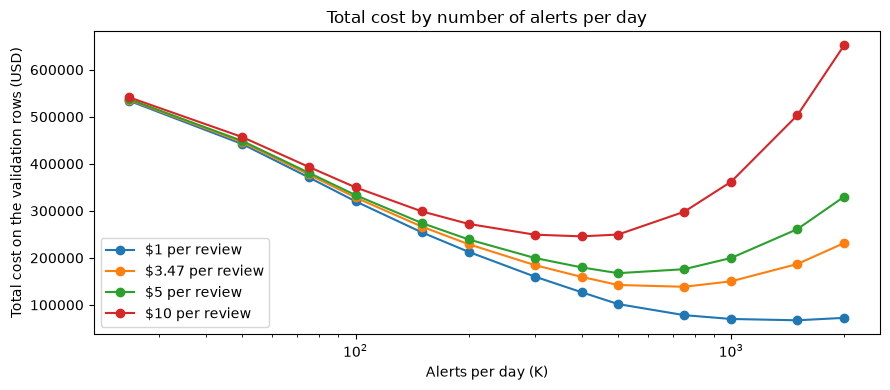

,best K per day,precision,recall,total cost
review cost,,,,
1.00,1500,0.074,0.968,67315.462
3.47,750,0.138,0.908,138576.143
5.00,500,0.194,0.861,167484.130
10.00,400,0.232,0.825,245738.663


In [6]:
# does the chosen K depend on the review cost?
sensitivity = []
fig, ax = plt.subplots(figsize=(9, 4))
for review_cost in [1, REVIEW_COST, 5, 10]:
    costs = []
    for k in K_VALUES:
        costs.append(alert_summary(top_k_per_day(val_scores, day_val, k), y_val, amount_val, day_val, review_cost)["total cost"])
    best = int(np.argmin(costs))
    best_summary = alert_summary(top_k_per_day(val_scores, day_val, K_VALUES[best]), y_val, amount_val, day_val, review_cost)
    sensitivity.append({"review cost": review_cost, "best K per day": K_VALUES[best], "precision": best_summary["precision"],
                        "recall": best_summary["recall"], "total cost": costs[best]})
    ax.plot(K_VALUES, costs, marker="o", label=f"${review_cost} per review")
ax.set_xscale("log")
ax.set_xlabel("Alerts per day (K)")
ax.set_ylabel("Total cost on the validation rows (USD)")
ax.set_title("Total cost by number of alerts per day")
ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(sensitivity).set_index("review cost").round(3))

**Takeaway: Choosing the Number of Alerts per Day**

- **Lowest cost at top 750:** At $3.47 per review, total cost is $138,576 compared with $630,473 without any alerts, a **78% reduction**. Precision is 13.8%, while recall is 90.8% and 91.5% of the total fraud amount is caught.

- **Small cost differences around the minimum:** Top 500 costs only 2.7% more and top 1,000 costs 8.4% more than top 750, giving some flexibility in choosing K.

- **Sensitivity to review cost:** The optimal K falls from 1,500 at $1 per review to 500 at $5 and 400 at $10. However, all are much higher than the roughly 60 daily alerts from the default 0.5 threshold.

- **Limitations of the 0.5 threshold:** It costs $404,641 and catches only 36.9% of the total fraud amount, performing similarly to top 50-75 alerts per day.

- **Review capacity:** Top 750 means reviewing about 26% of daily transactions (750 out of approximately 2,860). This may only be practical with quick or automated checks, such as cardholder verification messages. A smaller team could choose a lower K, but would miss more fraud. For example, top 100 catches 57.6% of fraud transactions with 64.7% precision.

We therefore use **top 750 alerts per day** for the final test evaluation, based on the lowest validation cost at $3.47 per review.

## 5. Test Run

We continue the same M2 retraining approach used on the validation set (notebook 06 Section 6) throughout the test period:

- **Retraining frequency:** A new model is trained every 7 days, starting from the first test day
- **Training data:** Each model uses all transactions with available labels, including training, validation and earlier test transactions. The 7-day label delay is applied, so only transactions at least 7 days before the block start are included
- **Encodings:** Recalculated using all transactions before each block starts, since they do not require fraud labels

We also test a **static model**, trained once at the start of the test period without further retraining, following notebook 05. Comparing the two shows whether regular retraining continues to improve performance on the test set.

**Saved outputs:** Both sets of test scores are saved in `results/ieee/final_test/` and reused on subsequent runs. The trained models are saved in `results/ieee/final_test/models/` (6 M2 models and 1 static model), named after the first day they predict. The last M2 model is the most recently trained version of our final model.

In [7]:
TEST_FIRST_DAY = int(day[is_test].min())
TEST_LAST_DAY = int(day[is_test].max())

# the trained CatBoost models of both runs
# load one with pd.read_pickle(path)
MODELS_DIR = RUNS_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)


# scores of the test rows, with a new model every 7 days (retrain=True) or one model for the whole period (retrain=False)
def test_scores(run_name, retrain):
    path = RUNS_DIR / f"{run_name}.pkl"
    if path.exists():
        return pd.read_pickle(path).loc[X.index[is_test]].to_numpy()

    start = time.time()
    scores = pd.Series(np.nan, index=X.index[is_test], dtype="float64")
    model = None
    for block_start in range(TEST_FIRST_DAY, TEST_LAST_DAY + 1, FREQUENCY):
        block = is_test & (day >= block_start) & (day < block_start + FREQUENCY)
        if retrain or model is None:
            fit_rows = day < block_start - LABEL_DELAY_DAYS
            encodings = fit_encodings(day < block_start)
            X_fit = apply_encodings(X[fit_rows], encodings)[selected_cols]
            model = CatBoostClassifier(random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False, **TUNED_SETTINGS)
            model.fit(X_fit, y[fit_rows], cat_features=cat_features)
            # each trained model is saved, named by the day it starts scoring
            pd.to_pickle(model, MODELS_DIR / f"{run_name}_block{block_start}.pkl")
            del X_fit
        X_block = apply_encodings(X[block], encodings)[selected_cols]
        scores[X.index[block]] = model.predict_proba(X_block)[:, 1]
    del model
    scores.to_pickle(path)
    print(f"{run_name}: done ({time.time() - start:.0f}s)")
    return scores.to_numpy()


test_m2 = test_scores("test_m2_tuned_115", retrain=True)
test_static = test_scores("test_static_tuned_115", retrain=False)
y_test = y[is_test].to_numpy()
day_test = day[is_test]
amount_test = X.loc[is_test, "TransactionAmt"].to_numpy(dtype="float64")

test_m2_tuned_115: done (3630s)
test_static_tuned_115: done (406s)


## 6. Test Results

### 6.1 Overall Performance

We evaluate the test set using the same metrics as notebook 06 Section 6, with **PR-AUC as the main metric**. The other classification metrics use the default 0.5 threshold.

We also include the final M2 validation results for comparison.

In [8]:
k = 100


def evaluate(name, scores, labels, days):
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": days, "y": labels, "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(labels, scores),
            "ROC-AUC": roc_auc_score(labels, scores),
            "precision": precision_score(labels, predictions, zero_division=0),
            "recall": recall_score(labels, predictions, zero_division=0),
            "F1": f1_score(labels, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


result_rows = [evaluate("final model, validation", val_scores, y_val, day_val),
               evaluate("final model, test", test_m2, y_test, day_test),
               evaluate("static, test", test_static, y_test, day_test)]
results = pd.DataFrame(result_rows).set_index("model")
display(results.round(4))
print(f"test fraud rate: {y_test.mean():.4f} | PR-AUC of the final model / fraud rate: {results.loc['final model, test', 'PR-AUC'] / y_test.mean():.1f}")
print(f"M2 - static on the test rows: {results.loc['final model, test', 'PR-AUC'] - results.loc['static, test', 'PR-AUC']:+.4f} PR-AUC")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
"final model, validation",0.6673,0.9374,0.8589,0.4619,0.6008,0.6467,1711,281,1993,90502
"final model, test",0.6223,0.9316,0.8096,0.4405,0.5705,0.5695,1790,421,2274,113623
"static, test",0.5829,0.9158,0.7984,0.4072,0.5394,0.5369,1655,418,2409,113626


test fraud rate: 0.0344 | PR-AUC of the final model / fraud rate: 18.1
M2 - static on the test rows: +0.0394 PR-AUC


### 6.2 PR-AUC per Test Week

We calculate PR-AUC for each test week to check how model performance changes over time.

In [9]:
test_week = (day_test - TEST_FIRST_DAY) // 7
weekly = []
for name, scores in [("final model (M2)", test_m2), ("static", test_static)]:
    for w in np.unique(test_week):
        rows_w = test_week == w
        weekly.append({"model": name, "week": int(w) + 1, "PR-AUC": average_precision_score(y_test[rows_w], scores[rows_w])})
weekly_table = pd.DataFrame(weekly).pivot_table(index="model", columns="week", values="PR-AUC", sort=False)
display(weekly_table.round(4))

week_info = pd.DataFrame({"week": test_week + 1, "day": day_test, "fraud": y_test}).groupby("week").agg(
    first_day=("day", "min"), last_day=("day", "max"), rows=("fraud", "size"), fraud_rate=("fraud", "mean"))
display(week_info.round(4))

week,1,2,3,4,5,6
model,,,,,,
final model (M2),0.5951,0.6585,0.6007,0.5614,0.6707,0.6532
static,0.5951,0.6299,0.5727,0.5096,0.6294,0.5700


,first_day,last_day,rows,fraud_rate
week,,,,
1,141,147,18123,0.0348
2,148,154,21443,0.0308
3,155,161,19811,0.0285
4,162,168,21038,0.0347
5,169,175,19941,0.0368
6,176,182,17752,0.0421


### 6.3 Alerts at the Chosen K

We evaluate the selected **top 750 alerts per day** on the test set and compare the results with the validation set at the same K.

In [10]:
alert_rows = []
for name, scores, labels, amounts, days in [("validation", val_scores, y_val, amount_val, day_val),
                                            ("test", test_m2, y_test, amount_test, day_test)]:
    row = {"rows": name, "K per day": CHOSEN_K}
    row.update(alert_summary(top_k_per_day(scores, days, CHOSEN_K), labels, amounts, days, REVIEW_COST))
    row["cost with no alerts"] = amounts[labels == 1].sum()
    row["saving vs no alerts"] = 1 - row["total cost"] / row["cost with no alerts"]
    alert_rows.append(row)
display(pd.DataFrame(alert_rows).set_index("rows").round(3))

,K per day,alerts per day,precision,recall,share of fraud amount caught,review cost,missed fraud amount,total cost,cost with no alerts,saving vs no alerts
rows,,,,,,,,,,
validation,750,740.182,0.138,0.908,0.915,84758.22,53817.923,138576.143,630473.490,0.780
test,750,750.000,0.117,0.909,0.914,109305.00,52293.190,161598.190,609934.336,0.735


**Takeaway: Test Results**

- **Lower test performance:** PR-AUC drops from 0.667 on validation to 0.622 on test (-0.045), but remains about 18 times the test fraud rate of 3.44%. ROC-AUC changes much less, from 0.937 to 0.932.

- **Performance at the 0.5 threshold:** Precision drops from 0.859 to 0.810 and recall from 0.462 to 0.441 compared to the validation set. Precision@100 per day also falls from 0.647 to 0.570.

- **Weekly variation:** PR-AUC ranges from 0.608 to 0.698 across validation weeks and 0.561 to 0.671 across test weeks. Part of the overall drop may therefore be due to normal weekly variation. Since M2 was also selected over M3 and M4 using validation results, its validation score may be slightly optimistic.

- **Benefit of retraining:** M2 achieves a test PR-AUC of 0.622 compared with 0.583 for the static model (+0.039), close to the +0.052 improvement on validation (notebook 05). Both models perform identically in week 1 because they use the same initial model. M2 performs better in all 5 later weeks, with the gap increasing from +0.029 in week 2 to +0.083 in week 6. This suggests that regular retraining helps the model keep up with changes in transaction patterns.

- **Top 750 performance on test:** Recall remains almost unchanged at 90.9% versus 90.8% on validation, while the share of fraud amount caught is 91.4% versus 91.5%. Precision is slightly lower (11.7% vs 13.8%), alongside a lower fraud rate (3.44% vs 3.92%). Total cost falls from $609,934 without alerts to $161,598, a 73.5% reduction, compared with 78.0% on validation.

Overall, M2 performs slightly worse on test but still benefits from regular retraining, and the selected top 750 alert rule maintains similar fraud coverage.